# 05 · System Integration & Demo

**Owner:** Peter Michael Angelo Rucakibungo (Member D) · **Plan reference:** Phase 4 · **Code:** [`src/app.py`](../src/app.py)

This notebook runs the finished command-line app and checks that the whole system behaves as the brief's flow diagram requires. It uses the three models trained in notebook 04:

| Step | Model (owner) | Function | Rule |
|---|---|---|---|
| 1. Face | Facial recognition (Member B) | `identify_face(image)` | A face must be detected, **and** its embedding must be close to the predicted member's enrolled face (cosine similarity ≥ threshold). |
| 2. Product | Product recommendation (Member A) | `predict_for_customer(customer_id)` | The face member is mapped to a customer (`config.MEMBER_TO_CUSTOMER`). The prediction is computed but **held**. |
| 3. Voice | Voiceprint verification (Member C) | `verify_voice(clip, expected_member)` | The voice's top prediction must be **the same member the face step recognised**, with probability ≥ threshold. |
| Display | | | Only if all three steps pass: show the product and the top 3 probabilities. |

```
Face ──fail──▶ ACCESS DENIED (voice not run, nothing predicted is shown)
  │ pass: member m
  ▼
Product for m's customer (computed, held)
  ▼
Voice ──not recognised / sounds like another member──▶ ACCESS DENIED (held prediction discarded)
  │ pass: voice is m
  ▼
Display product + top 3
```

**The multimodal logic.** The voice is not just checked against "any member": it must belong to *the person the face step recognised*. Someone with a member's photo still needs that member's voice. This cross-modal consistency check is what scenario 5 tests.

Contents:
1. Setup and thresholds
2. The six required scenarios (`python src/app.py --demo`)
3. Why each decision was made
4. Single-transaction and interactive use, and error handling
5. Robustness beyond scenario 6
6. Known limitation: a real non-member's voice
7. Conclusions

## 1. Setup and thresholds

In [1]:
import contextlib
import io
import json
import sys
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PY = sys.executable                    # the same Python environment for the ! commands below

from src import app, config

warnings.filterwarnings("ignore", category=UserWarning)
with contextlib.redirect_stdout(io.StringIO()):
    C = app.load_components()          # loads the 3 models + face detector once
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)
plt.rcParams["figure.dpi"] = 80

# Plot styling: the same validated palette as notebooks 01, 02 and 04.
INK, INK_2, GRID, SURFACE, MUTED = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb", "#a8a79f"
PASS = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "legend.frameon": False,
})

meta = {name: json.loads(p.read_text()) for name, p in
        [("face", config.FACE_META_PATH), ("voice", config.VOICE_META_PATH), ("product", config.PRODUCT_META_PATH)]}
pd.DataFrame([
    {"Step": "1. Face", "Algorithm": meta["face"]["algorithm"], "Decision rule": f"cosine similarity >= {meta['face']['threshold']}"},
    {"Step": "2. Product", "Algorithm": meta["product"]["algorithm"], "Decision rule": "top category (held until step 3 passes)"},
    {"Step": "3. Voice", "Algorithm": meta["voice"]["algorithm"],
     "Decision rule": f"top prediction == face member and P >= {meta['voice']['threshold']}"},
]).set_index("Step")

,Algorithm,Decision rule
Step,,
1. Face,Logistic Regression,cosine similarity >= 0.509
2. Product,Logistic Regression,top category (held until step 3 passes)
3. Voice,XGBoost,top prediction == face member and P >= 0.533


The thresholds are read from the `*_meta.json` files saved in notebook 04, so the app and this notebook always use the tuned values. They are never hard-coded in `app.py`.

**Member → customer mapping (simulation assumption).** The team members are not in the transaction data, so each one is mapped to a real customer who has transactions and a social profile (`config.MEMBER_TO_CUSTOMER`):

In [2]:
pd.DataFrame([{"member": m, "name": config.MEMBER_NAMES[m], "customer_id": c}
              for m, c in config.MEMBER_TO_CUSTOMER.items()]).set_index("member")

,name,customer_id
member,,
hassan,Hassan Adelani Luqman,187
emma,Emma Tiffany Umwari,101
parfait,Parfait Shema Semana,114
peter,Peter Michael Angelo Rucakibungo,120


## 2. The six required scenarios

This is the exact command used in the demo video. It runs the 6 scenarios from Plan.md Section 4.4 and prints every stage with its timing. For scenario 6, the app generates the augmented inputs itself, using the same augmentation code as the pipelines: Peter's photo rotated by −15°, and Peter's clip with new background noise at 20 dB SNR. These files are not in the repository.

In [3]:
!cd "{ROOT}" && "{PY}" src/app.py --demo

Loading models… 

done (4.2 s)



Scenario 1: Authorised member (Member A, Hassan)
Expected: product displayed
------------------------------------------------------------------------------
  Face : data/images/hassan/hassan_neutral_01.jpg
  Voice: Audio_features/data/audio/raw/hassan_yes_approve_1.wav
[1/3] Facial recognition…         

✅ hassan (similarity 0.97 >= 0.51)  (0.13 s)
[2/3] Product recommendation…     

computed for customer 187, held until the voice check passes  (0.02 s)
[3/3] Voiceprint verification…    

✅ hassan (confidence 0.95 >= 0.53)  (0.07 s)
✅ ACCESS GRANTED. Recommended product for Hassan Adelani Luqman (customer 187): Groceries
     1. Groceries    30.2%
     2. Books        22.6%
     3. Electronics  17.3%
     Total time 0.22 s

Scenario 2: Member B (Emma): different expression and phrase
Expected: product displayed
------------------------------------------------------------------------------
  Face : data/images/emma/emma_smiling_01.jpg
  Voice: Audio_features/data/audio/raw/emma_confirm_transaction_1.wav
[1/3] Facial recognition…         

... (5 outputs left out)

✅ parfait (similarity 0.90 >= 0.51)  (0.19 s)
[2/3] Product recommendation…     computed for customer 114, held until the voice check passes  (0.01 s)
[3/3] Voiceprint verification…    

❌ identity mismatch: voice sounds like 'peter', face was 'parfait'  (0.08 s)
❌ ACCESS DENIED at the voice step. The held prediction is discarded; no product shown.

Scenario 6: Robustness: augmented face and voice of Member D (Peter)
Expected: product displayed
------------------------------------------------------------------------------
  Face : data/images/peter/peter_smiling_01.jpg, rotated -15 degrees (generated)
  Voice: Audio_features/.../peter_confirm_transaction_1.wav + background noise at 20 dB SNR (generated)
[1/3] Facial recognition…         

✅ peter (similarity 0.92 >= 0.51)  (0.13 s)
[2/3] Product recommendation…     computed for customer 120, held until the voice check passes  (0.01 s)
[3/3] Voiceprint verification…    

✅ peter (confidence 0.97 >= 0.53)  (0.04 s)
✅ ACCESS GRANTED. Recommended product for Peter Michael Angelo Rucakibungo (customer 120): Sports
     1. Sports       32.6%
     2. Books        26.0%
     3. Clothing     14.9%
     Total time 0.18 s

Summary
------------------------------------------------------------------------------
   Scenario                             Expected                    Result
1. Member A: own face + own voice       product displayed           ✅ product displayed (Groceries)
2. Member B: other expression + phrase  product displayed           ✅ product displayed (Books)
3. Non-member face                      denied at face step         ✅ denied at face step
4. Member C face + non-member voice     denied at voice step        ✅ denied at voice (identity mismatch)
5. Member C face + Member D voice       denied: identity mismatch   ✅ denied at voice (identity mismatch)
6. Member D: augmented face + voice     product displayed           ✅ product displayed (Spor

**Interpretation:**
- **All 6 scenarios behave as required.** Both authorised members get a product. The non-member face is stopped at step 1, before any prediction is shown. Both voice attacks are stopped at step 3, and the held prediction is discarded.
- **Scenario 2** uses Emma's *smiling* photo with the *"Confirm transaction"* phrase, while scenario 1 uses Hassan's neutral photo with *"Yes, approve"*. So the app works for either phrase and any of the 3 expressions.
- **Scenario 4** is denied at the voice step, as required. The model hears the non-member as Hassan, so the reason is *identity mismatch* rather than *voice not recognised*. Section 6 explains why this matters.
- **Speed:** loading the models takes about 3–4 s once. After that, a whole transaction takes under a second on a laptop (0.2–0.6 s here).

## 3. Why each decision was made

The demo is run again silently to collect the scores behind each decision: face similarity, and the voice probability for the member the face step recognised.

In [4]:
with contextlib.redirect_stdout(io.StringIO()):
    results = app.run_demo()

rows = []
for r in results:
    o = r["outcome"]
    claimed = o.member
    rows.append({
        "#": r["#"], "scenario": r["short"], "expected": r["expected"], "result": r["result"],
        "as expected": "yes" if r["as_expected"] else "NO",
        "face similarity": o.face["similarity"],
        "face closest": o.face["closest_member"],
        "voice heard as": o.voice["predicted_member"] if o.voice else "(not reached)",
        "P(voice = face member)": o.voice["probabilities"][claimed] if o.voice else np.nan,
        "seconds": r["seconds"],
    })
scen = pd.DataFrame(rows).set_index("#")
print(f"{(scen['as expected'] == 'yes').sum()}/{len(scen)} scenarios as expected")
scen

6/6 scenarios as expected


,scenario,expected,result,as expected,face similarity,face closest,voice heard as,P(voice = face member),seconds
#,,,,,,,,,
1,Member A: own face + own voice,product displayed,product displayed (Groceries),yes,0.969,hassan,hassan,0.951,0.39
2,Member B: other expression + phrase,product displayed,product displayed (Books),yes,0.917,emma,emma,0.969,0.36
3,Non-member face,denied at face step,denied at face step,yes,0.224,emma,(not reached),NaN,0.08
4,Member C face + non-member voice,denied at voice step,denied at voice (identity mismatch),yes,0.927,parfait,hassan,0.065,0.35
5,Member C face + Member D voice,denied: identity mismatch,denied at voice (identity mismatch),yes,0.895,parfait,peter,0.012,0.24
6,Member D: augmented face + voice,product displayed,product displayed (Sports),yes,0.924,peter,peter,0.971,0.23


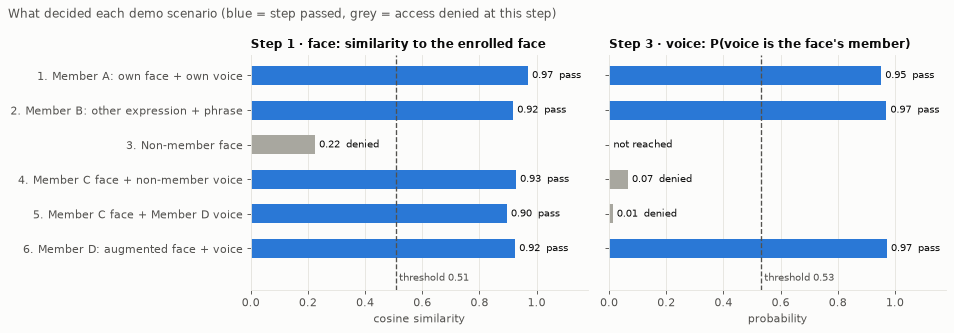

In [5]:
t_face, t_voice = meta["face"]["threshold"], meta["voice"]["threshold"]
labels = [f"{i}. {s}" for i, s in zip(scen.index, scen["scenario"])][::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
panels = [(axes[0], scen["face similarity"][::-1], t_face, "Step 1 · face: similarity to the enrolled face"),
          (axes[1], scen["P(voice = face member)"][::-1], t_voice, "Step 3 · voice: P(voice is the face's member)")]
for ax, vals, t, title in panels:
    y = np.arange(len(vals))
    passed = (vals >= t).to_numpy()
    if ax is axes[1]:   # identity must also be the top prediction
        heard = scen["voice heard as"][::-1].to_numpy()
        face_m = [results[i - 1]["outcome"].member for i in scen.index[::-1]]
        passed = passed & (heard == np.array(face_m, dtype=object))
    ax.barh(y, vals.fillna(0), height=0.55, color=np.where(passed, PASS, MUTED))
    ax.axvline(t, color=INK_2, ls="--", lw=1.2)
    ax.text(t + 0.01, -0.85, f"threshold {t:.2f}", color=INK_2, fontsize=9, va="center")
    for yi, v, ok in zip(y, vals, passed):
        txt = "not reached" if np.isnan(v) else f"{v:.2f}  {'pass' if ok else 'denied'}"
        ax.text((0 if np.isnan(v) else v) + 0.015, yi, txt, va="center", fontsize=9, color=INK)
    ax.set_xlim(0, 1.18)
    ax.set_ylim(-1.2, len(vals) - 0.4)
    ax.set_yticks(y, labels)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
axes[0].set_xlabel("cosine similarity")
axes[1].set_xlabel("probability")
fig.suptitle("What decided each demo scenario (blue = step passed, grey = access denied at this step)",
             x=0.01, ha="left", fontsize=11, color=INK_2)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "system_demo_decisions.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:**
- **Face step:** every member photo scores 0.90–0.97, far above the 0.51 threshold. That includes the rotated photo in scenario 6. The non-member scores about 0.22, so the margin is wide on both sides.
- **Voice step:** genuine clips give their own member 0.95–0.97. In scenarios 4 and 5, the voice gives Parfait almost no probability, because the model hears Hassan and Peter. Both are denied because the voice does not match the face, and the held product is never shown.
- Scenario 3 never reaches the voice step. The app stops at the first failed check, so a stranger learns nothing about the prediction.

## 4. Single-transaction and interactive use, and error handling

**One transaction from the command line.** The exit code is 0 when access is granted, 1 when denied, and 2 for a bad input. A script can use it directly.

In [6]:
!cd "{ROOT}" && "{PY}" src/app.py --face data/images/peter/peter_neutral_01.jpg --voice Audio_features/data/audio/raw/peter_yes_approve_1.wav; echo "exit code: $?"

Multimodal Biometric Product Recommender
Loading models… 

done (3.9 s)
  Face : data/images/peter/peter_neutral_01.jpg
  Voice: Audio_features/data/audio/raw/peter_yes_approve_1.wav
[1/3] Facial recognition…         

✅ peter (similarity 0.94 >= 0.51)  (0.29 s)
[2/3] Product recommendation…     computed for customer 120, held until the voice check passes  (0.02 s)
[3/3] Voiceprint verification…    

✅ peter (confidence 0.97 >= 0.53)  (0.06 s)
✅ ACCESS GRANTED. Recommended product for Peter Michael Angelo Rucakibungo (customer 120): Sports
     1. Sports       32.6%
     2. Books        26.0%
     3. Clothing     14.9%
     Total time 0.38 s


exit code: 0


**Interactive mode.** `python src/app.py` with no arguments asks for the face image first. It asks for the voice clip **only if the face is accepted**, matching the flow. A wrong path is asked for again, and `q` quits. Here, typed input is simulated with a pipe: a typo, then a valid photo, then a voice clip.

In [7]:
import subprocess
typed = ["data/images/hassan/typo.jpg",                               # a typo: asked again
         "data/images/hassan/hassan_smiling_01.jpg",                  # face
         "Audio_features/data/audio/raw/hassan_confirm_transaction_1.wav",   # voice
         "n"]                                                         # no more transactions
r = subprocess.run([PY, "src/app.py"], cwd=ROOT, input="\n".join(typed) + "\n", capture_output=True, text=True)
# a pipe does not echo what was typed, so put each answer back after its prompt
prompts = ["Face image path: ", 'transaction"): ', "[y/N]: "]
out, shown = r.stdout, ""
for answer in typed:
    i = min((out.find(q) + len(q) for q in prompts if q in out), default=None)
    if i is None:
        break
    shown += out[:i] + answer + "\n"
    out = out[i:]
print(shown + out.rstrip())

Multimodal Biometric Product Recommender: interactive mode
Enter file paths (you can drag a file into the terminal). Type q to quit.

Loading models… done (4.1 s)
Face image path: data/images/hassan/typo.jpg
  ❌ face file not found: data/images/hassan/typo.jpg. Try again, or type q to quit.
Face image path: data/images/hassan/hassan_smiling_01.jpg
  Face : data/images/hassan/hassan_smiling_01.jpg
[1/3] Facial recognition…         ✅ hassan (similarity 0.94 >= 0.51)  (0.13 s)
[2/3] Product recommendation…     computed for customer 187, held until the voice check passes  (0.02 s)
Voice clip path (say "Yes, approve" or "Confirm transaction"): Audio_features/data/audio/raw/hassan_confirm_transaction_1.wav
[3/3] Voiceprint verification…    ✅ hassan (confidence 0.98 >= 0.53)  (0.10 s)
✅ ACCESS GRANTED. Recommended product for Hassan Adelani Luqman (customer 187): Groceries
     1. Groceries    30.2%
     2. Books        22.6%
     3. Electronics  17.3%
     Total time 0.25 s

Another transact

**Bad inputs are handled with a clear message, not a traceback.** The cases below are a missing file, a file of the wrong type, a corrupt image, and an image with no face in it.

In [8]:
tmp = Path(tempfile.mkdtemp())
(tmp / "corrupt.jpg").write_text("not really an image")
import cv2
cv2.imwrite(str(tmp / "no_face.jpg"), np.full((300, 300, 3), 128, np.uint8))   # plain grey picture
voice = "Audio_features/data/audio/raw/peter_yes_approve_1.wav"
for face in ["data/images/peter/missing.jpg", "README.md", tmp / "corrupt.jpg", tmp / "no_face.jpg"]:
    r = subprocess.run([PY, "src/app.py", "--face", str(face), "--voice", voice], cwd=ROOT, capture_output=True, text=True)
    lines = [l for l in (r.stdout + r.stderr).splitlines() if any(k in l for k in ("Error", "ACCESS", "[1/3]"))]
    print(f"$ python src/app.py --face {Path(face).name} --voice {Path(voice).name}")
    print("\n".join("  " + l for l in lines) + f"\n  exit code: {r.returncode}\n")

$ python src/app.py --face missing.jpg --voice peter_yes_approve_1.wav
  ❌ Error: face file not found: data/images/peter/missing.jpg
  exit code: 2



$ python src/app.py --face README.md --voice peter_yes_approve_1.wav
  ❌ Error: face file must be one of .bmp, .jpeg, .jpg, .png, .webp (got '.md'): README.md
  exit code: 2



$ python src/app.py --face corrupt.jpg --voice peter_yes_approve_1.wav
  [1/3] Facial recognition…         ❌ could not read the image
  ❌ Error: could not read face image corrupt.jpg (UnidentifiedImageError: is it a real image file?)
  exit code: 2



$ python src/app.py --face no_face.jpg --voice peter_yes_approve_1.wav
  [1/3] Facial recognition…         ❌ no face detected  (0.08 s)
  ❌ ACCESS DENIED at the face step. Voice check not run; no product shown.
  exit code: 1



## 5. Robustness beyond scenario 6

Scenario 6 shows one augmented pair. Here every member's inputs are tested the same way.
- **Faces:** all 3 photos of each member, in every one of the 8 image augmentations.
- **Voices:** both clips of each member, with *new* background noise at three levels. Each level uses 3 random seeds, none of them the seed used for the training features.

In [9]:
ip, tf, tv = C.ip, C.tf, C.tv
ap = tv.ap

face_rows = []
for m in config.MEMBERS:
    for p in sorted((config.IMAGES_DIR / m).glob("*.jpg")):
        for aug, img in ip.augment(ip.load_image(p)).items():
            r = tf.identify_face(img)
            face_rows.append({"member": m, "augmentation": aug, "accepted": r["accepted"] and r["member"] == m})
face_rob = pd.DataFrame(face_rows).pivot_table(index="augmentation", columns="member", values="accepted", aggfunc="mean")

voice_rows = []
noise_dir = Path(tempfile.mkdtemp())
for m in config.MEMBERS:
    for clip in sorted((config.AUDIO_PIPELINE_DIR / "data" / "audio" / "raw").glob(f"{m}_*.wav")):
        y = ap.load_clip(clip)
        voice_rows.append({"member": m, "condition": "original", "accepted": tv.verify_voice(clip, m)["approved"]})
        for snr in [20, 15, 10]:
            for seed in [1, 7, 123]:
                f = noise_dir / f"{clip.stem}_{snr}_{seed}.wav"
                sf.write(f, ap.add_noise(y, snr_db=snr, rng=np.random.default_rng(seed)), ap.SR, subtype="FLOAT")
                voice_rows.append({"member": m, "condition": f"noise {snr} dB SNR",
                                   "accepted": tv.verify_voice(f, m)["approved"]})
voice_rob = pd.DataFrame(voice_rows).pivot_table(index="condition", columns="member", values="accepted", aggfunc="mean")
voice_rob = voice_rob.loc[["original", "noise 20 dB SNR", "noise 15 dB SNR", "noise 10 dB SNR"]]

print(f"Faces accepted as the right member: {sum(r['accepted'] for r in face_rows)}/{len(face_rows)}")
display((face_rob * 100).round(0).astype(int).astype(str) + "%")
print("Voice clips accepted for their own member (2 clips per member; 3 noise seeds per level):")
display((voice_rob * 100).round(0).astype(int).astype(str) + "%")

Faces accepted as the right member: 108/108


member,emma,hassan,parfait,peter
augmentation,,,,
blur,100%,100%,100%,100%
brighter,100%,100%,100%,100%
darker,100%,100%,100%,100%
flip,100%,100%,100%,100%
grayscale,100%,100%,100%,100%
noise,100%,100%,100%,100%
original,100%,100%,100%,100%
rotate_m15,100%,100%,100%,100%
rotate_p15,100%,100%,100%,100%


Voice clips accepted for their own member (2 clips per member; 3 noise seeds per level):


member,emma,hassan,parfait,peter
condition,,,,
original,100%,100%,100%,100%
noise 20 dB SNR,100%,100%,100%,100%
noise 15 dB SNR,100%,100%,100%,100%
noise 10 dB SNR,100%,67%,33%,100%


**Interpretation:**
- **Faces are fully robust:** every augmentation of every photo is accepted as the right member. Rotation, flip, greyscale, lighting, blur and noise make no difference, because the face is detected and aligned before the embedding is taken.
- **Voices are robust to moderate noise but not to heavy noise.** At 20 dB and 15 dB SNR (a quiet room to a busy office), every clip is still accepted. At 10 dB, where the noise is nearly as loud as the voice, some of Hassan's and Parfait's clips are rejected. That is the safe direction to fail: the member is asked to repeat the phrase, and nobody else is let in.
- *Caveat:* every member recorded each phrase once, so these noisy clips are new versions of recordings the model was trained on. They test robustness to noise, not to a new recording. Notebook 04 (Section 9) gives the held-out results for new recordings: 44% of genuine clips accepted.

## 6. Known limitation: a real non-member's voice

The project has 4 real non-member voice clips: 2 from Ketia (recorded by Member C) and 2 in `data/unauthorized/voices/`. Scenario 4 uses one of the latter, which is denied. Here, all 4 are tried with Parfait's face, the setup of scenario 4.

In [10]:
lim = []
for clip in sorted((config.AUDIO_PIPELINE_DIR / "data" / "audio" / "unauthorized").glob("*.wav")) + \
            sorted(config.UNAUTHORIZED_VOICES_DIR.glob("*.wav")):
    with contextlib.redirect_stdout(io.StringIO()):
        o = app.run_transaction(config.IMAGES_DIR / "parfait" / "parfait_neutral_01.jpg", clip)
    lim.append({"non-member clip": app._rel(clip), "voice heard as": o.voice["predicted_member"],
                "confidence": o.voice["confidence"],
                "result": "APPROVED (wrong)" if o.approved else f"denied: {o.reason}"})
pd.DataFrame(lim).set_index("non-member clip")

,voice heard as,confidence,result
non-member clip,,,
Audio_features/data/audio/unauthorized/Ketia_approve.wav,parfait,0.856,APPROVED (wrong)
Audio_features/data/audio/unauthorized/Ketia_comfirm.wav,parfait,0.934,APPROVED (wrong)
data/unauthorized/voices/approve.wav,hassan,0.853,"denied: identity mismatch: voice sounds like 'hassan', face was 'parfait'"
data/unauthorized/voices/confirm.wav,hassan,0.584,"denied: identity mismatch: voice sounds like 'hassan', face was 'parfait'"


**Interpretation (stated plainly for the report and video):**
- **Ketia's voice is accepted as Parfait's.** The voice model hears Ketia as Parfait with about 0.86–0.93 confidence, so a person holding *Parfait's photo* and speaking in Ketia's voice would be approved. The other non-member is denied, but only because the model hears that voice as Hassan's, not because it recognises a stranger.
- **Why:** the voice model was trained on one take of each phrase per member, 8 recordings in total. With so little data it learns "which of the 4 members is this closest to", not "is this one of the 4 at all". An `unknown` class trained on non-member clips was tested in notebook 04 (Section 9.1). It did not carry over to a new stranger, so it was not adopted.
- **What protects the system today:** strangers are stopped by the **face** step, which rejected all 27 real non-member face rows in notebook 04. The voice step reliably catches *the wrong member* (97% of other-member attempts rejected in held-out tests), which is the identity-mismatch check. The weak case is narrow but real: an attacker needs a member's photo **and** a voice that happens to resemble that member.
- **Fix:** 3–4 more takes of each phrase from every member, then rerun the audio pipeline and `src/train_voice_model.py`. Neither `app.py` nor this notebook needs any change.

## 7. Conclusions

| Phase 4 requirement (Plan.md) | Evidence |
|---|---|
| Implements the flow: face → product (held) → voice → display | `src/app.py`; Sections 2–3: the product is only shown after step 3 passes |
| Cross-modal check: voice must match the face's member | Scenarios 4 and 5 are denied for identity mismatch |
| Non-interactive, interactive and demo modes | Sections 2 and 4 |
| Stage-by-stage output with timing; graceful handling of bad files | Sections 2 and 4 (missing, wrong type, corrupt, no face) |
| All 6 scenarios run without errors and behave as expected | Section 2 summary and Section 3 table: **6/6** |
| Robustness to augmented inputs | Scenario 6; Section 5 for every member |

**Limitations to report:**
- A real non-member's voice can pass the voice step if it resembles the member whose face was shown (Section 6).
- Heavy background noise (around 10 dB SNR) can make a member repeat the phrase (Section 5).
- Team members are mapped to existing customers for the product prediction, a simulation assumption.

All of these trace back to the small amount of biometric data (1 take per expression and phrase). More recordings are the most useful next step for the whole system.